In [ ]:
import os, gc, torch, pywt
import numpy as np
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets, transforms, models
from torchvision.models.feature_extraction import create_feature_extractor
from tqdm import tqdm
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_curve, auc
from sklearn.preprocessing import label_binarize
from PIL import Image

# 1. --- MOUNT GOOGLE DRIVE ---
from google.colab import drive
drive.mount('/content/drive')

# 2. --- SETUP INDIVIDUAL DRIVE PATHS ---
# Replace the paths below with the ACTUAL paths to your folders on Drive.
# Tip: Use the folder icon on the left sidebar, find your folder, right-click and "Copy path".

# The folder containing the corn test images (unzipped)
TEST_PATH  = '/content/drive/MyDrive/resnet50-individual-test-results/tomato-test-dataset'

# The path to your saved ResNet-50 .pth model file
TRAINED_MODEL_PATH = '/content/drive/MyDrive/ResNet50_Final_Results/best_plant_model.pth'

# The folder where you want to save the corn test results
NEW_RESULTS_DIR = '/content/drive/MyDrive/resnet50-individual-test-results'
os.makedirs(NEW_RESULTS_DIR, exist_ok=True)

# 3. --- DEVICE SETUP ---
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# 4. --- PATH VERIFICATION ---
print("--- Verification ---")
if os.path.exists(TEST_PATH):
    print(f"✅ Test data found at: {TEST_PATH}")
else:
    print(f"❌ ERROR: Test path not found! Check your path string.")

if os.path.exists(TRAINED_MODEL_PATH):
    print(f"✅ Model found at: {TRAINED_MODEL_PATH}")
else:
    print(f"❌ ERROR: Model file not found! Check your path string.")

print(f"Results will be saved to: {NEW_RESULTS_DIR}")
print(f"Running on: {DEVICE}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
--- Verification ---
✅ Test data found at: /content/drive/MyDrive/resnet50-individual-test-results/tomato-test-dataset
✅ Model found at: /content/drive/MyDrive/ResNet50_Final_Results/best_plant_model.pth
Results will be saved to: /content/drive/MyDrive/resnet50-individual-test-results
Running on: cpu


In [ ]:
class AdvancedDWTExtractor:
    def __init__(self, wavelet='db8', level=3):
        self.wavelet = wavelet
        self.level = level

    def denoise_coeffs(self, coeffs):
        new_coeffs = [coeffs[0]]
        for detail_level in coeffs[1:]:
            thresholded = []
            for d in detail_level:
                sigma = np.median(np.abs(d)) / 0.6745
                if sigma > 1e-6:
                    thresh = sigma * np.sqrt(2 * np.log(d.size + 1e-12))
                    thresholded.append(pywt.threshold(d, thresh, mode='soft'))
                else:
                    thresholded.append(d)
            new_coeffs.append(tuple(thresholded))
        return new_coeffs

    def get_stats(self, data):
        energy = np.sum(data**2) / (data.size + 1e-12)
        std = np.std(data)
        entropy = -np.sum(data**2 * np.log(data**2 + 1e-12)) / (data.size + 1e-12)
        return [energy, std, entropy]

    def __call__(self, img_gray):
        coeffs = pywt.wavedec2(img_gray, self.wavelet, level=self.level)
        coeffs = self.denoise_coeffs(coeffs)
        features = []
        features.extend(self.get_stats(coeffs[0]))
        for detail_level in coeffs[1:]:
            for band in detail_level:
                features.extend(self.get_stats(band))
        return torch.tensor(features).float()

class DWTTransform:
    def __init__(self, wavelet='db8', size=(224,224)):
        self.extractor = AdvancedDWTExtractor(wavelet=wavelet, level=3)
        self.size = size
    def __call__(self, img):
        img_gray = np.array(img.resize(self.size).convert('L')) / 255.0
        return self.extractor(img_gray)

In [ ]:
class SEBlock(nn.Module):
    def __init__(self, channels, reduction=16):
        super().__init__()
        self.fc = nn.Sequential(
            nn.Linear(channels, channels // reduction, bias=False),
            nn.ReLU(inplace=True),
            nn.Linear(channels // reduction, channels, bias=False),
            nn.Sigmoid()
        )
    def forward(self, x):
        b, c, _, _ = x.size()
        y = x.mean(dim=(2,3))
        y = self.fc(y).view(b, c, 1, 1)
        return x * y

class ConvBNReLU(nn.Module):
    def __init__(self, in_ch, out_ch, kernel_size=1):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, kernel_size, padding=kernel_size//2, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True)
        )
    def forward(self, x): return self.block(x)

class HybridModel(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        # Changed to ResNet-50
        resnet = models.resnet50(weights=None)
        self.spatial_extractor = create_feature_extractor(resnet, return_nodes={'layer4': 'feat'})

        # ResNet-50 layer4 output is 2048 channels
        self.refine = ConvBNReLU(2048, 2048, kernel_size=1)
        self.se = SEBlock(2048)

        self.freq_mlp = nn.Sequential(
            nn.Linear(30, 128), nn.BatchNorm1d(128), nn.ReLU(inplace=True),
            nn.Linear(128, 256), nn.BatchNorm1d(256), nn.ReLU(inplace=True)
        )
        self.fusion = nn.Sequential(
            nn.Linear(2048 + 256, 512), nn.BatchNorm1d(512), nn.ReLU(inplace=True), nn.Dropout(0.3)
        )
        self.classifier = nn.Linear(512, num_classes)

    def forward(self, img, dwt):
        spatial = self.spatial_extractor(img)['feat']
        spatial = self.se(self.refine(spatial)).mean(dim=(2,3))
        freq = self.freq_mlp(dwt)
        fused = torch.cat([spatial, freq], dim=1)
        return self.classifier(self.fusion(fused))

In [ ]:
class CustomDataset(Dataset):
    def __init__(self, folder_path):
        self.dataset = datasets.ImageFolder(folder_path)
        self.classes = self.dataset.classes
        self.rgb_transform = transforms.Compose([
            transforms.Resize((224,224)),
            transforms.ToTensor(),
            transforms.Normalize(mean=[0.485,0.456,0.406], std=[0.229,0.224,0.225])
        ])
        self.dwt_transform = DWTTransform()

    def __len__(self): return len(self.dataset)
    def __getitem__(self, idx):
        img, label = self.dataset[idx]
        return self.rgb_transform(img), self.dwt_transform(img), label

test_dataset = CustomDataset(TEST_PATH)
test_loader  = DataLoader(test_dataset, batch_size=32, shuffle=False, num_workers=2)

print(f"Test Classes: {test_dataset.classes}")

Test Classes: ['Tomato___Bacterial_spot', 'Tomato___Early_blight', 'Tomato___Late_blight', 'Tomato___Leaf_Mold', 'Tomato___Septoria_leaf_spot', 'Tomato___Spider_mites Two-spotted_spider_mite', 'Tomato___Target_Spot', 'Tomato___Tomato_Yellow_Leaf_Curl_Virus', 'Tomato___Tomato_mosaic_virus', 'Tomato___healthy']


In [ ]:
# 1. --- LOAD CHECKPOINT ---
checkpoint = torch.load(TRAINED_MODEL_PATH, map_location=DEVICE)
model_classes = checkpoint['classes']
model = HybridModel(len(model_classes)).to(DEVICE)
model.load_state_dict(checkpoint['model_state'])
model.eval()

# 2. --- MAP CORN CLASSES TO MODEL INDICES ---
corn_indices = []
for local_name in test_dataset.classes:
    # Matches local folder name to global model category
    match = [i for i, name in enumerate(model_classes) if local_name.lower() in name.lower()]
    if match:
        corn_indices.append(match[0])
    else:
        print(f"Warning: No match for {local_name}")

print(f"Mapped {test_dataset.classes} to Global Indices {corn_indices}")

# 3. --- RUN TESTING ---
y_true_global, y_pred_global, y_probs = [], [], []

with torch.no_grad():
    # mininterval=5.0 used to prevent IOPub error
    for img, dwt, labels in tqdm(test_loader, desc="Testing ResNet-50", mininterval=5.0):
        img, dwt, labels = img.to(DEVICE), dwt.to(DEVICE), labels.to(DEVICE)
        outputs = model(img, dwt)

        current_labels_global = [corn_indices[l] for l in labels.cpu().numpy()]
        y_probs.extend(torch.softmax(outputs, dim=1).cpu().numpy())
        y_true_global.extend(current_labels_global)
        y_pred_global.extend(outputs.max(1)[1].cpu().numpy())

Mapped ['Tomato___Bacterial_spot', 'Tomato___Early_blight', 'Tomato___Late_blight', 'Tomato___Leaf_Mold', 'Tomato___Septoria_leaf_spot', 'Tomato___Spider_mites Two-spotted_spider_mite', 'Tomato___Target_Spot', 'Tomato___Tomato_Yellow_Leaf_Curl_Virus', 'Tomato___Tomato_mosaic_virus', 'Tomato___healthy'] to Global Indices [15, 16, 17, 18, 19, 20, 21, 22, 23, 24]


Testing ResNet-50: 100%|██████████| 57/57 [09:22<00:00,  9.87s/it]


                                               precision    recall  f1-score   support

                      Tomato___Bacterial_spot       1.00      0.99      0.99       213
                        Tomato___Early_blight       0.99      1.00      1.00       100
                         Tomato___Late_blight       1.00      0.97      0.98       191
                           Tomato___Leaf_Mold       1.00      1.00      1.00        96
                  Tomato___Septoria_leaf_spot       0.96      0.99      0.98       178
Tomato___Spider_mites Two-spotted_spider_mite       1.00      1.00      1.00       168
                         Tomato___Target_Spot       1.00      0.97      0.99       142
       Tomato___Tomato_Yellow_Leaf_Curl_Virus       1.00      1.00      1.00       536
                 Tomato___Tomato_mosaic_virus       1.00      1.00      1.00        38
                             Tomato___healthy       1.00      1.00      1.00       160

                                    micro

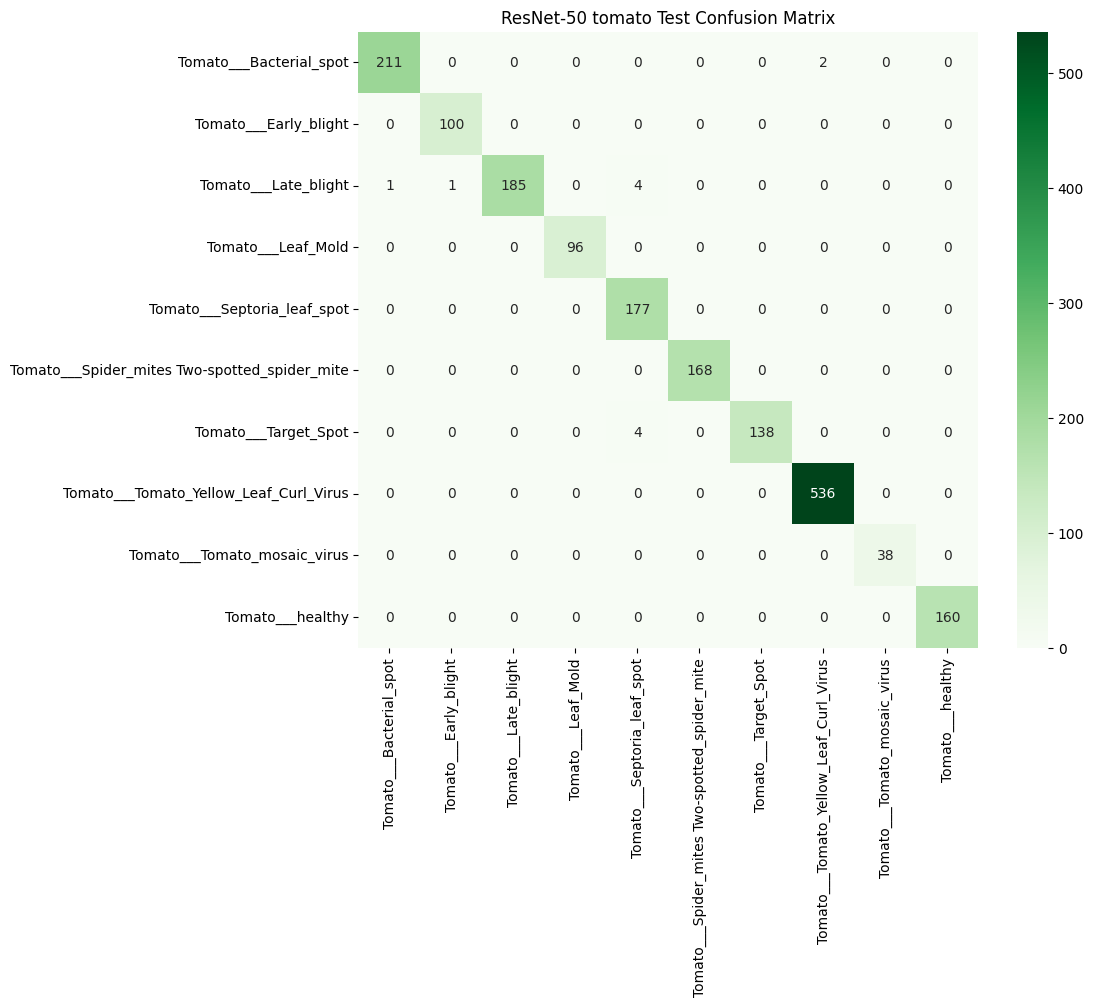

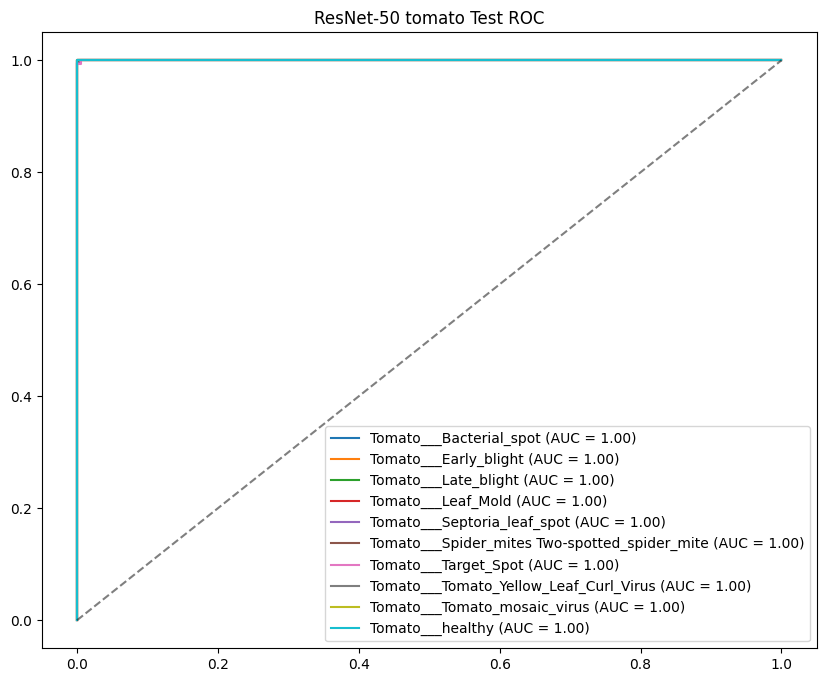

In [ ]:
# 1. Classification Report
report = classification_report(y_true_global, y_pred_global,
                            labels=corn_indices, target_names=test_dataset.classes)
print(report)
with open(os.path.join(NEW_RESULTS_DIR, 'tomato-resnet50_classification_report.txt'), 'w') as f:
    f.write(report)

# 2. Confusion Matrix
cm = confusion_matrix(y_true_global, y_pred_global, labels=corn_indices)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens',
            xticklabels=test_dataset.classes, yticklabels=test_dataset.classes)
plt.title('ResNet-50 tomato Test Confusion Matrix')
plt.savefig(os.path.join(NEW_RESULTS_DIR, 'tomato_confusion_matrix.png'))
plt.show()

# 3. ROC Curve
y_true_bin = label_binarize(y_true_global, classes=range(len(model_classes)))
plt.figure(figsize=(10, 8))
for i, global_idx in enumerate(corn_indices):
    fpr, tpr, _ = roc_curve(y_true_bin[:, global_idx], np.array(y_probs)[:, global_idx])
    plt.plot(fpr, tpr, label=f'{test_dataset.classes[i]} (AUC = {auc(fpr, tpr):.2f})')

plt.plot([0, 1], [0, 1], 'k--', alpha=0.5)
plt.legend(loc='lower right')
plt.title('ResNet-50 tomato Test ROC')
plt.savefig(os.path.join(NEW_RESULTS_DIR, 'tomato_roc_curve.png'))
plt.show()

In [ ]:
test_acc = accuracy_score(y_true_global, y_pred_global)
total_samples = len(y_true_global)
correct = sum(np.array(y_true_global) == np.array(y_pred_global))

print("-" * 40)
print(f"RESNET-50 TEST ACCURACY: {test_acc*100:.2f}%")
print(f"Total Images: {total_samples} | Correct: {correct}")
print("-" * 40)

# Save summary to file
with open(os.path.join(NEW_RESULTS_DIR, 'tomato-final_accuracy_summary.txt'), 'w') as f:
    f.write(f"Model: ResNet-50 Hybrid\nTest Accuracy: {test_acc*100:.2f}%\nTotal Samples: {total_samples}")

print(f"Results successfully saved to: {NEW_RESULTS_DIR}")

----------------------------------------
RESNET-50 TEST ACCURACY: 99.29%
Total Images: 1822 | Correct: 1809
----------------------------------------
Results successfully saved to: /content/drive/MyDrive/resnet50-individual-test-results
